In [1]:
     from google.colab import drive
     drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

DATA = "/content/drive/MyDrive/funnel_analysis/"
OUT = "/content/reports/"
os.makedirs(OUT, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

funnel = pd.read_csv(DATA + "funnel_overall.csv")
brand = pd.read_csv(DATA + "funnel_by_brand.csv")
ret = pd.read_csv(DATA + "cohort_retention.csv", parse_dates=["cohort_week"])

funnel

,step,users,pct_of_first,conv_from_prev,loss_from_prev
0,1. view,1597754,100.00,NaN,NaN
1,2. cart,270236,16.91,16.91,83.09
2,3. purchase,71848,4.50,26.59,73.41


In [7]:
brand.head()

,brand,viewers,carted,purchased,view_to_cart_pct,cart_to_purchase_pct
0,runail,193942,39345,15016,20.29,38.16
1,irisk,153750,30345,11201,19.74,36.91
2,grattol,106093,21308,7385,20.08,34.66
3,estel,92359,13677,4632,14.81,33.87
4,kapous,92035,9859,3280,10.71,33.27


In [8]:
ret.head()

,cohort_week,week_n,active_users,cohort_size,retention_pct
0,2019-10-14,0,75870,75870,100.00
1,2019-10-14,1,7332,75870,9.66
2,2019-10-14,2,4724,75870,6.23
3,2019-10-14,3,4071,75870,5.37
4,2019-10-14,4,3630,75870,4.78


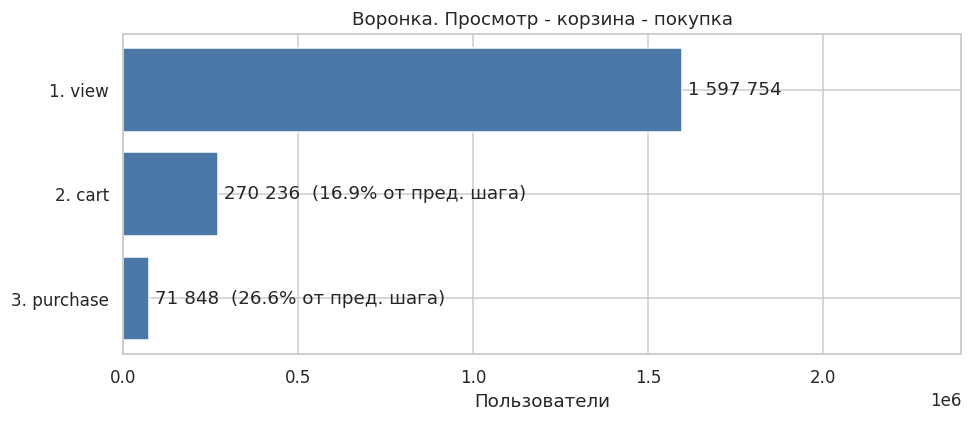

In [10]:
f = funnel.copy()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(f["step"][::-1], f["users"][::-1], color="#4C78A8")

for bar, (_, row) in zip(bars, f[::-1].iterrows()):
    label = f"{int(row['users']):,}".replace(",", " ")
    if pd.notna(row["conv_from_prev"]):
        label += f"  ({row['conv_from_prev']:.1f}% от пред. шага)"
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, " " + label, va="center")

ax.set_xlim(0, f["users"].max() * 1.5)
ax.set_title("Воронка. Просмотр - корзина - покупка")
ax.set_xlabel("Пользователи")
plt.tight_layout()
plt.savefig(OUT + "funnel.png", dpi=150)
plt.show()

In [11]:
steps = funnel.dropna(subset=["loss_from_prev"]).copy()
worst = steps.loc[steps["loss_from_prev"].idxmax()]

print(f"Максимальная потеря на шаге: {worst['step']}")
print(f"Теряется: {worst['loss_from_prev']:.1f}% пользователей")
print(f"Общая конверсия просмотр → покупка: {funnel['pct_of_first'].iloc[-1]:.2f}%")

Максимальная потеря на шаге: 2. cart
Теряется: 83.1% пользователей
Общая конверсия просмотр → покупка: 4.50%


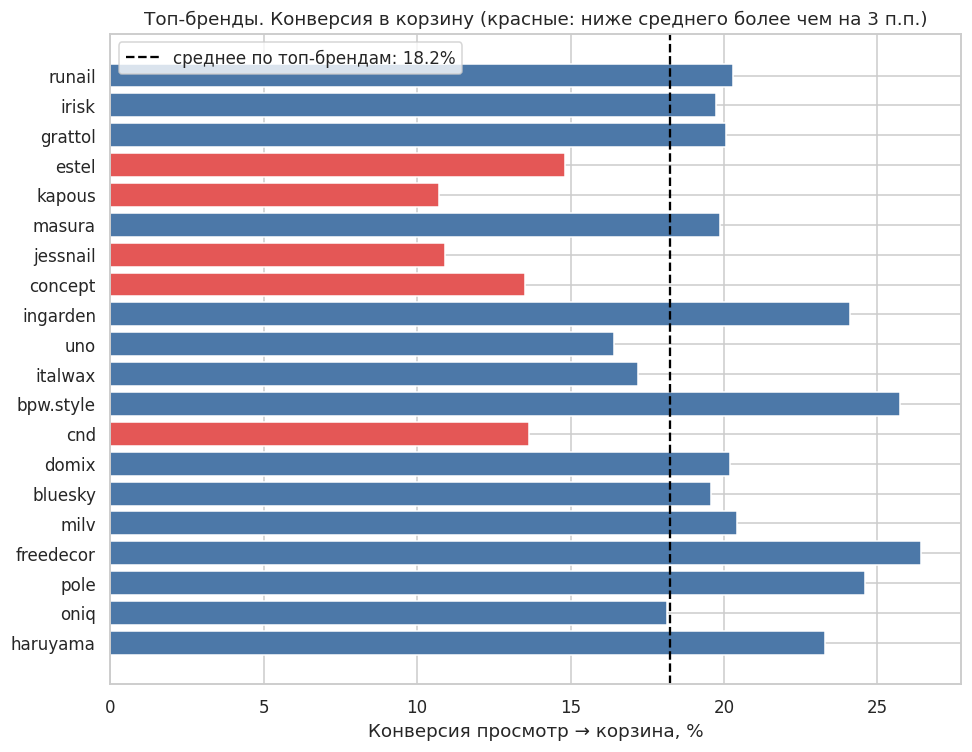

In [13]:
b = brand.sort_values("viewers", ascending=False).copy()
avg_v2c = (b["carted"].sum() / b["viewers"].sum()) * 100

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#E45756" if v < avg_v2c - 3 else "#4C78A8" for v in b["view_to_cart_pct"]]
ax.barh(b["brand"][::-1], b["view_to_cart_pct"][::-1], color=colors[::-1])
ax.axvline(avg_v2c, color="black", linestyle="--", label=f"среднее по топ-брендам: {avg_v2c:.1f}%")
ax.set_xlabel("Конверсия просмотр → корзина, %")
ax.set_title("Топ-бренды. Конверсия в корзину (красные: ниже среднего более чем на 3 п.п.)")
ax.legend()
plt.tight_layout()
plt.savefig(OUT + "brands_view_to_cart.png", dpi=150)
plt.show()

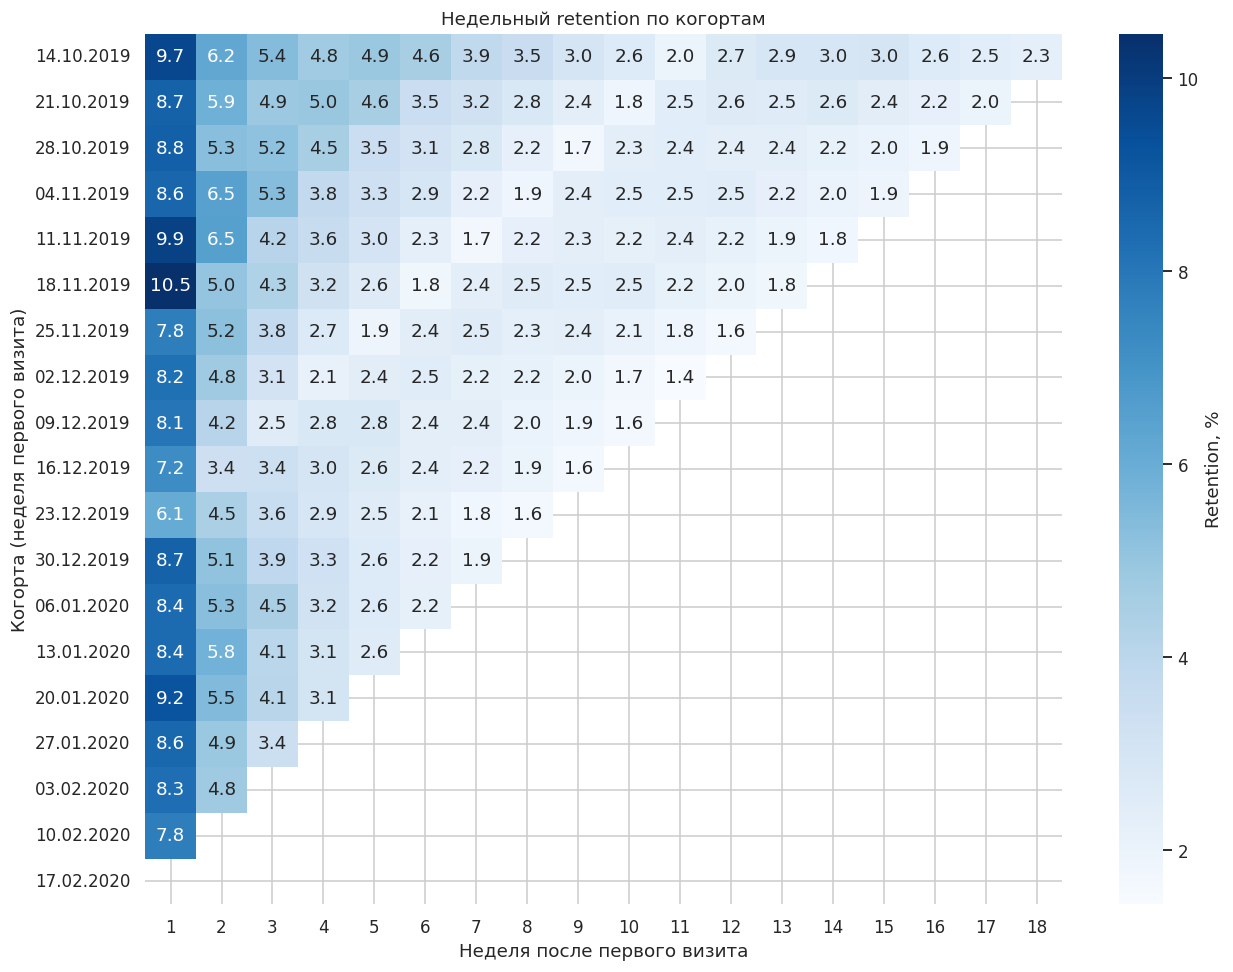

In [15]:
m = ret.pivot(index="cohort_week", columns="week_n", values="retention_pct")
m = m.drop(columns=0)
m.index = m.index.strftime("%d.%m.%Y")

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(m, annot=True, fmt=".1f", cmap="Blues",
            cbar_kws={"label": "Retention, %"}, ax=ax)
ax.set_title("Недельный retention по когортам")
ax.set_xlabel("Неделя после первого визита")
ax.set_ylabel("Когорта (неделя первого визита)")
plt.tight_layout()
plt.savefig(OUT + "retention_heatmap.png", dpi=150)
plt.show()

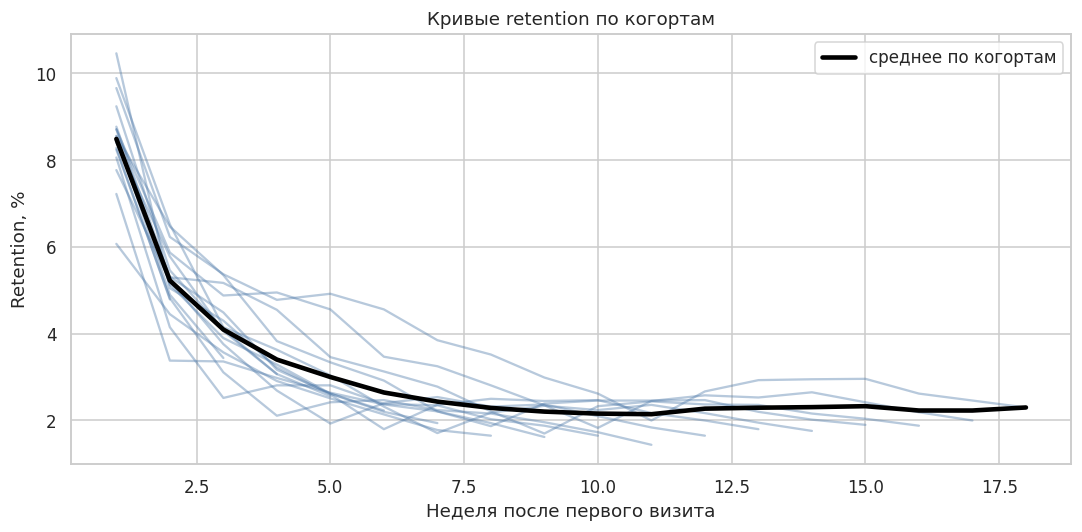

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
r = ret[ret["week_n"] > 0]
for cohort, g in r.groupby("cohort_week"):
    ax.plot(g["week_n"], g["retention_pct"], alpha=0.4, color="#4C78A8")

avg = r.groupby("week_n")["retention_pct"].mean()
ax.plot(avg.index, avg.values, color="black", linewidth=3, label="среднее по когортам")
ax.set_xlabel("Неделя после первого визита")
ax.set_ylabel("Retention, %")
ax.set_title("Кривые retention по когортам")
ax.legend()
plt.tight_layout()
plt.savefig(OUT + "retention_curves.png", dpi=150)
plt.show()

In [21]:
ret.groupby("week_n")["cohort_week"].nunique()

,cohort_week
week_n,
0,19
1,18
2,17
3,16
4,15
5,14
6,13
7,12
8,11


In [22]:
N = 9

sub = ret[ret["week_n"] == N].copy()
n = len(sub)
total = sub["retention_pct"].sum()
sub["others_avg"] = (total - sub["retention_pct"]) / (n - 1)
sub["diff_pp"] = sub["retention_pct"] - sub["others_avg"]

result = sub.sort_values("diff_pp")[["cohort_week", "cohort_size", "retention_pct", "others_avg", "diff_pp"]]
print(f"Сравнение когорт на неделе {N} (всего когорт: {n})")
result

Сравнение когорт на неделе 9 (всего когорт: 10)


,cohort_week,cohort_size,retention_pct,others_avg,diff_pp
144,2019-12-16,69697,1.62,2.270000,-0.650000
46,2019-10-28,69266,1.70,2.261111,-0.561111
133,2019-12-09,72917,1.88,2.241111,-0.361111
121,2019-12-02,69455,1.96,2.232222,-0.272222
79,2019-11-11,68901,2.34,2.190000,0.150000
28,2019-10-21,72230,2.35,2.188889,0.161111
108,2019-11-25,76529,2.37,2.186667,0.183333
63,2019-11-04,72713,2.39,2.184444,0.205556
94,2019-11-18,77180,2.45,2.177778,0.272222
9,2019-10-14,75870,2.99,2.117778,0.872222


In [23]:
from statsmodels.stats.proportion import proportions_ztest

weak = sub.sort_values("diff_pp").iloc[0]
rest = sub[sub["cohort_week"] != weak["cohort_week"]]

counts = [weak["active_users"], rest["active_users"].sum()]
nobs   = [weak["cohort_size"],  rest["cohort_size"].sum()]
z, p = proportions_ztest(counts, nobs)
print(f"Когорта {weak['cohort_week'].date()}: {weak['retention_pct']:.2f}% против {rest['active_users'].sum() / rest['cohort_size'].sum() * 100:.2f}%")
print(f"z = {z:.2f}, p-value = {p:.4f}")

Когорта 2019-12-16: 1.62% против 2.28%
z = -11.25, p-value = 0.0000


In [24]:
print("=== ДЛЯ РЕЗЮМЕ ===")
print(f"Шаг воронки с максимальной потерей: {worst['step']} ({worst['loss_from_prev']:.1f}%)")
print(f"Когорта-аутсайдер: {weak['cohort_week'].date()}")
print(f"Неделя: {N}")
print(f"Отставание от остальных: {abs(weak['diff_pp']):.1f} п.п.")

=== ДЛЯ РЕЗЮМЕ ===
Шаг воронки с максимальной потерей: 2. cart (83.1%)
Когорта-аутсайдер: 2019-12-16
Неделя: 9
Отставание от остальных: 0.6 п.п.


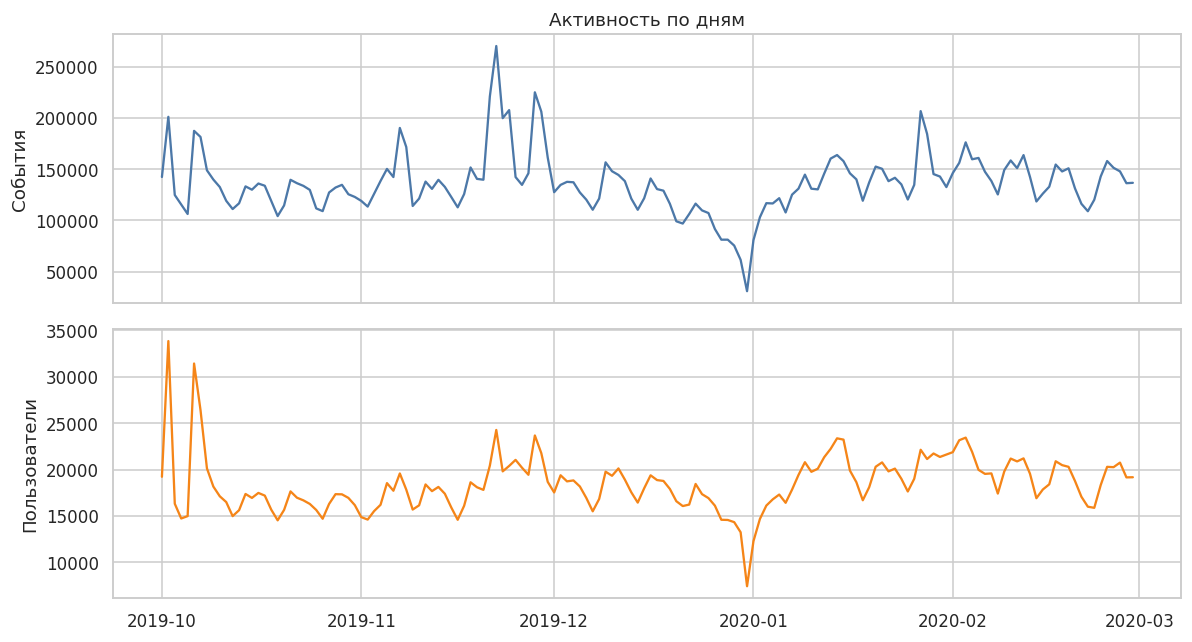

In [25]:
daily = pd.read_csv(DATA + "daily_activity.csv", parse_dates=["day"])
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(daily["day"], daily["events"], color="#4C78A8"); axes[0].set_ylabel("События")
axes[1].plot(daily["day"], daily["users"], color="#F58518"); axes[1].set_ylabel("Пользователи")
axes[0].set_title("Активность по дням")
plt.tight_layout()
plt.savefig(OUT + "daily_activity.png", dpi=150)
plt.show()

In [26]:
import shutil
from google.colab import files

shutil.make_archive("/content/reports", "zip", OUT)
files.download("/content/reports.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
print("Проблема. 83,1% пользователей, просмотревших товары, не добавляют ничего в корзину. У брендов kapous, jessnail, concept и cnd конверсия просмотр - корзина составляет 11,8% против 20,0% у остальных топ-брендов.")

Проблема. 83,1% пользователей, просмотревших товары, не добавляют ничего в корзину. У брендов kapous, jessnail, concept и cnd конверсия просмотр - корзина составляет 11,8% против 20,0% у остальных топ-брендов.


In [32]:
print("Гипотеза. Если для товаров этих брендов улучшить карточку (блок отзывов и рейтинга, выбор оттенка или объема на одном экране, заметная кнопка «В корзину», блок «С этим покупают»), то доля просмотревших, добавивших товар в корзину, вырастет.")

Гипотеза. Если для товаров этих брендов улучшить карточку (блок отзывов и рейтинга, выбор оттенка или объема на одном экране, заметная кнопка «В корзину», блок «С этим покупают»), то доля просмотревших, добавивших товар в корзину, вырастет.


In [33]:
print("Целевая аудитория. Пользователи, впервые открывшие карточку товара целевых брендов во время теста.")

Целевая аудитория. Пользователи, впервые открывшие карточку товара целевых брендов во время теста.


In [35]:
target = ["kapous", "jessnail", "concept", "cnd"]
t = brand[brand["brand"].isin(target)]
o = brand[~brand["brand"].isin(target)]

baseline = t["carted"].sum() / t["viewers"].sum()
leader   = o["carted"].sum() / o["viewers"].sum()
gap      = leader - baseline

print(f"База (целевые бренды): {baseline:.2%}")
print(f"Остальные бренды:      {leader:.2%}")
print(f"Разрыв:                {gap * 100:.1f} п.п.")

p_optimistic   = baseline + gap / 3
p_conservative = baseline * 1.10
print(f"Оптимистично: {p_optimistic:.2%} (+{(p_optimistic - baseline) * 100:.1f} п.п.)")
print(f"Консервативно: {p_conservative:.2%} (+{(p_conservative - baseline) * 100:.1f} п.п.)")

База (целевые бренды): 11.82%
Остальные бренды:      19.97%
Разрыв:                8.2 п.п.
Оптимистично: 14.54% (+2.7 п.п.)
Консервативно: 13.00% (+1.2 п.п.)


In [36]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
import numpy as np

def n_per_group(p_base, p_new, alpha=0.05, power=0.8):
    es = proportion_effectsize(p_new, p_base)
    return int(np.ceil(NormalIndPower().solve_power(es, alpha=alpha, power=power, ratio=1)))

print("Консервативно:", n_per_group(baseline, p_conservative))
print("Оптимистично: ", n_per_group(baseline, p_optimistic))

rows = []
for rel in [0.05, 0.10, 0.15, 0.20]:
    new = baseline * (1 + rel)
    rows.append({
        "относительный прирост": f"+{rel:.0%}",
        "целевая конверсия": f"{new:.2%}",
        "пользователей на группу": n_per_group(baseline, new),
    })
pd.DataFrame(rows)

Консервативно: 12209
Оптимистично:  2426


,относительный прирост,целевая конверсия,пользователей на группу
0,+5%,12.41%,47849
1,+10%,13.00%,12209
2,+15%,13.59%,5533
3,+20%,14.18%,3172


In [39]:
daily = t["viewers"].sum() / 146
need_total = 2 * n_per_group(baseline, p_conservative)
days_needed = int(np.ceil(need_total / daily))
print(f"Трафик = {daily:,.0f} польз./день")
print(f"Нужно пользователей: {need_total:,} - {days_needed} дн.")
print(f"Фактический срок (минимум 14 дней): {max(days_needed, 14)} дн.")

# что можно поймать за 14 дней
n14 = daily * 14 / 2
es14 = NormalIndPower().solve_power(nobs1=n14, alpha=0.05, power=0.8, ratio=1)
print(f"За 14 дней на группу {n14:,.0f} польз., минимальный обнаружимый эффект h = {es14:.3f}")

Трафик = 1,850 польз./день
Нужно пользователей: 24,418 - 14 дн.
Фактический срок (минимум 14 дней): 14 дн.
За 14 дней на группу 12,948 польз., минимальный обнаружимый эффект h = 0.035


In [40]:
funnel

,step,users,pct_of_first,conv_from_prev,loss_from_prev
0,1. view,1597754,100.00,NaN,NaN
1,2. cart,270236,16.91,16.91,83.09
2,3. purchase,71848,4.50,26.59,73.41
